In [1]:
from helper_functions.get_data_dictionary_target_X_y_imports import *

Loaded: 
      data: the entire dataset.
      dictionary: the data dictionary.
      X: the features columns with 'inhospital_mortality', 'studyid_adm', 'lengthadm' dropped.
      y: the target column.


In [2]:
X_old = X.copy()
social_features = dictionary[dictionary.Category.str.contains('Social')].Feature.tolist()
social_features

['travelmethod_adm',
 'traveldist_adm',
 'badhealthduration_adm',
 'caregiver_adm_new',
 'caregiverage_adm',
 'caregivermarried_adm',
 'momalive_adm',
 'momageknown_adm',
 'momagefirstpregknown_adm',
 'momedu_adm',
 'momhiv_adm',
 'watersource_adm',
 'waterpure_adm',
 'cookfuel_adm___1',
 'cookfuel_adm___2',
 'cookfuel_adm___3',
 'cookfuel_adm___4',
 'cookfuel_adm___5',
 'cookfuel_adm___6',
 'cookfuel_adm___7',
 'cookfuel_adm___8',
 'cookloc_adm',
 'lightfuel_adm',
 'tobacco_adm',
 'bednet_adm',
 'momage_adm',
 'momagefirstpreg_adm',
 'householdsize_adm',
 'alivechildren_adm',
 'deadchildren_adm']

In [3]:
X.replace('Dont know', 'Unknown', inplace=True)

for col in X.select_dtypes(include='object'):
    Col = X[col]
    missing_values = Col.isna().sum()
    has_unknown = "Unknown" in Col.unique()
    if missing_values and has_unknown:
        print(f"Feature {col} has {missing_values} missing values that can be replaced with 'Unknown'.")

Feature vaccmeasles_adm has 2 missing values that can be replaced with 'Unknown'.
Feature vaccdpt_adm has 1 missing values that can be replaced with 'Unknown'.
Feature priorweekantimal_adm has 1 missing values that can be replaced with 'Unknown'.
Feature priorhosp_adm has 5 missing values that can be replaced with 'Unknown'.
Feature prioryearwheeze_adm has 2 missing values that can be replaced with 'Unknown'.
Feature exclbreastfed_adm has 1 missing values that can be replaced with 'Unknown'.
Feature totalbreastfed_adm has 2 missing values that can be replaced with 'Unknown'.
Feature badhealthduration_adm has 4 missing values that can be replaced with 'Unknown'.
Feature momhiv_adm has 5 missing values that can be replaced with 'Unknown'.


In [4]:
for col in X.select_dtypes(include='object'):
    Col = X[col]
    missing_values = Col.isna().sum()
    has_unknown = "Unknown" in Col.unique()
    print(col, "\t", Col.unique())
    print ("[bold red] There are unknown values in this column.[/bold red]") if has_unknown else None

sex_adm 	 ['Female' 'Male']
spo2onoxy_adm 	 ['No' 'Yes' nan]
oxygenavail_adm 	 ['Oxygen available and not being used' 'Oxygen available but not enough'
 'Oxygen available and being used' 'Oxygen not available']
respdistress_adm 	 ['No' 'Yes' nan]
caprefill_adm 	 ['No' 'Yes' nan]
bcseye_adm 	 ['Watches or follows' 'Fails to watch or follow' nan]
bcsmotor_adm 	 ['Localizes painful stimulus' 'Withdraws limb from painful stimulus'
 'No response or inappropriate response']
bcsverbal_adm 	 ['Cries appropriately with pain, or, if verbal, speaks'
 'Moan or abnormal cry with pain' 'No vocal response to pain' nan]
admitabx_adm___1 	 ['Checked' 'Unchecked']
admitabx_adm___2 	 ['Unchecked' 'Checked']
admitabx_adm___3 	 ['Unchecked' 'Checked']
admitabx_adm___4 	 ['Unchecked' 'Checked']
admitabx_adm___5 	 ['Unchecked' 'Checked']
admitabx_adm___6 	 ['Unchecked' 'Checked']
admitabx_adm___7 	 ['Unchecked' 'Checked']
admitabx_adm___8 	 ['Unchecked' 'Checked']
admitabx_adm___9 	 ['Checked' 'Unchecked']
a

In [5]:
indices_to_drop = []
for idx in X.index:
    values = X.loc[idx, social_features].values
    if 'Unknown' in values:
        indices_to_drop.append(idx)
cleaned_X = X[social_features].drop(index=indices_to_drop).dropna().copy()
cleaned_y = y.loc[cleaned_X.index]
df = pd.concat([cleaned_X,cleaned_y], axis=1).reset_index(drop=True)

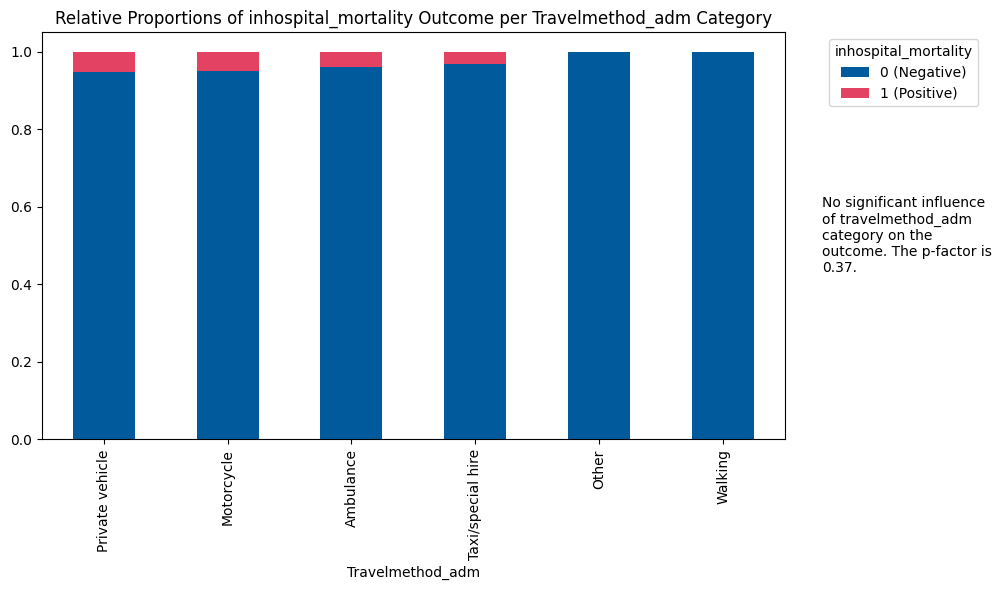

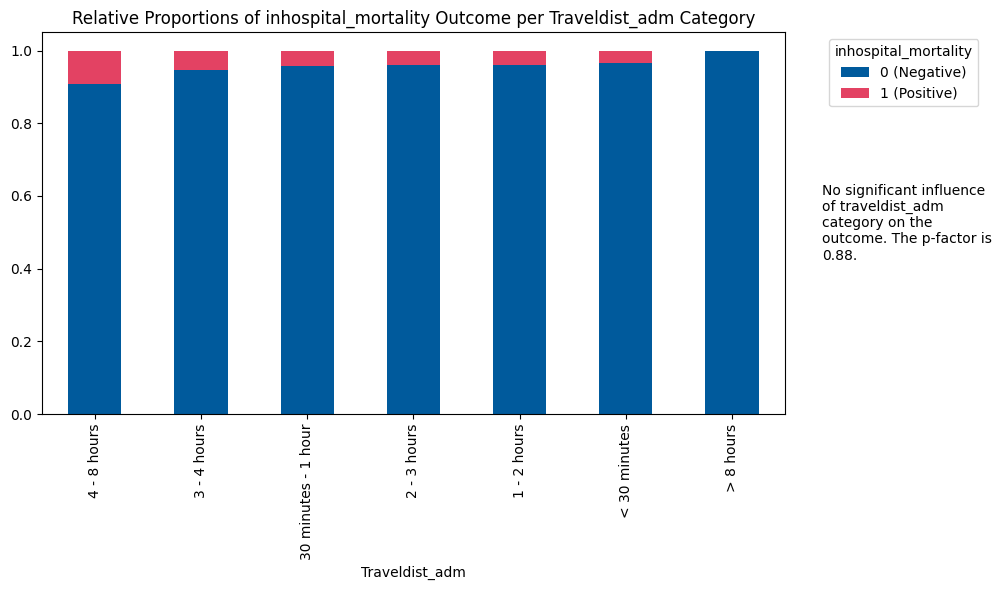

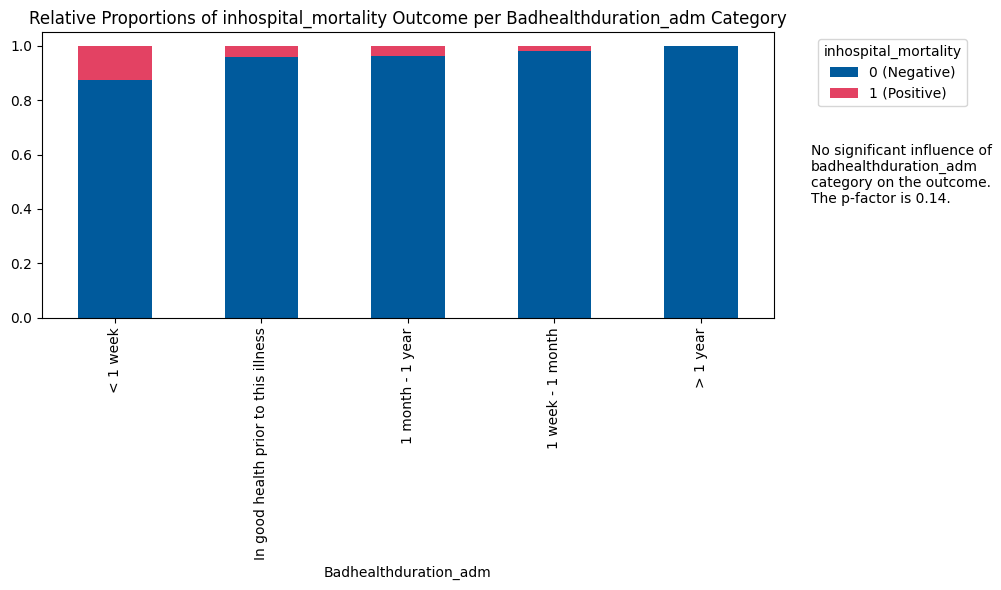

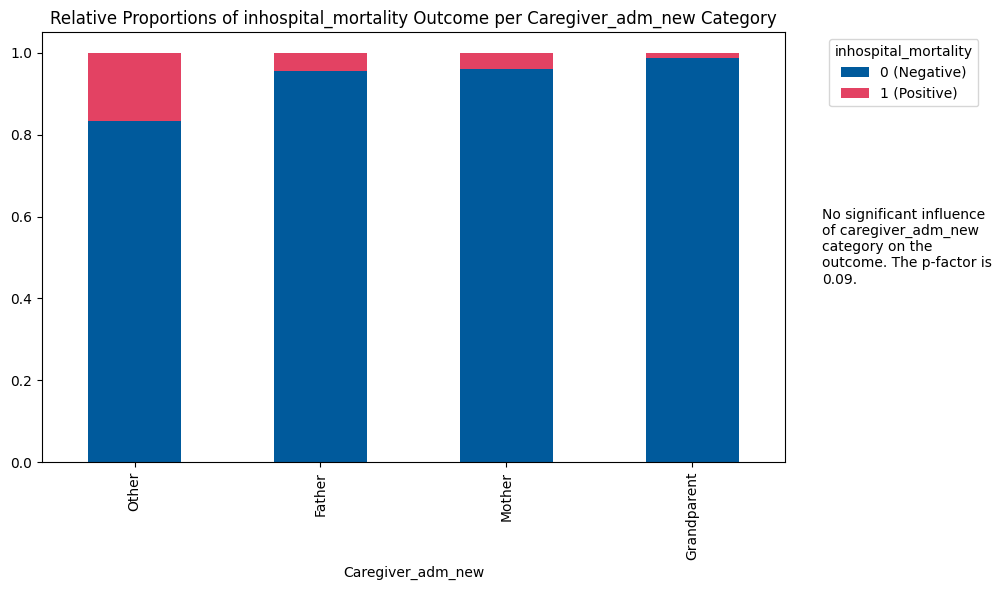

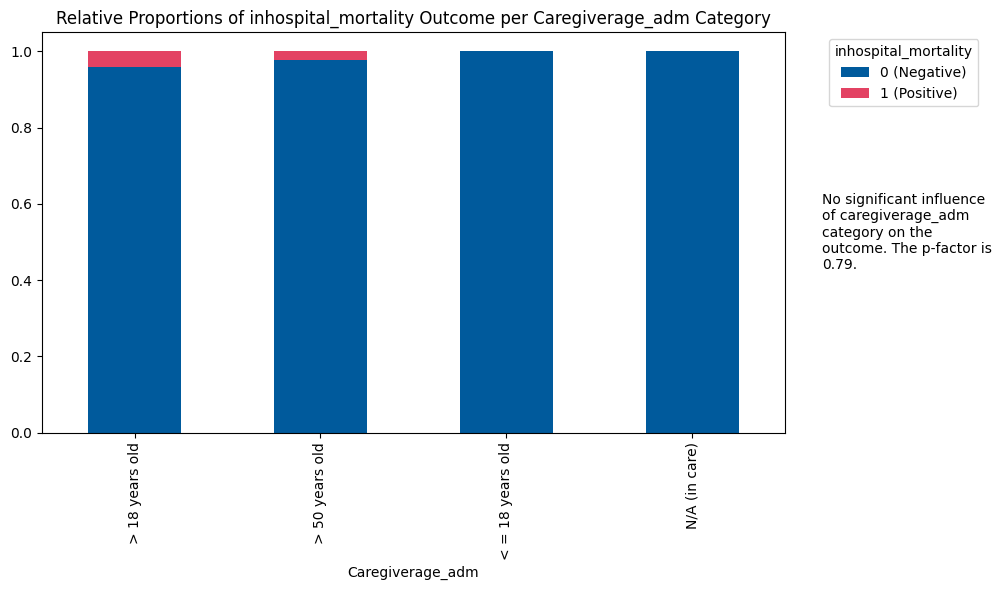

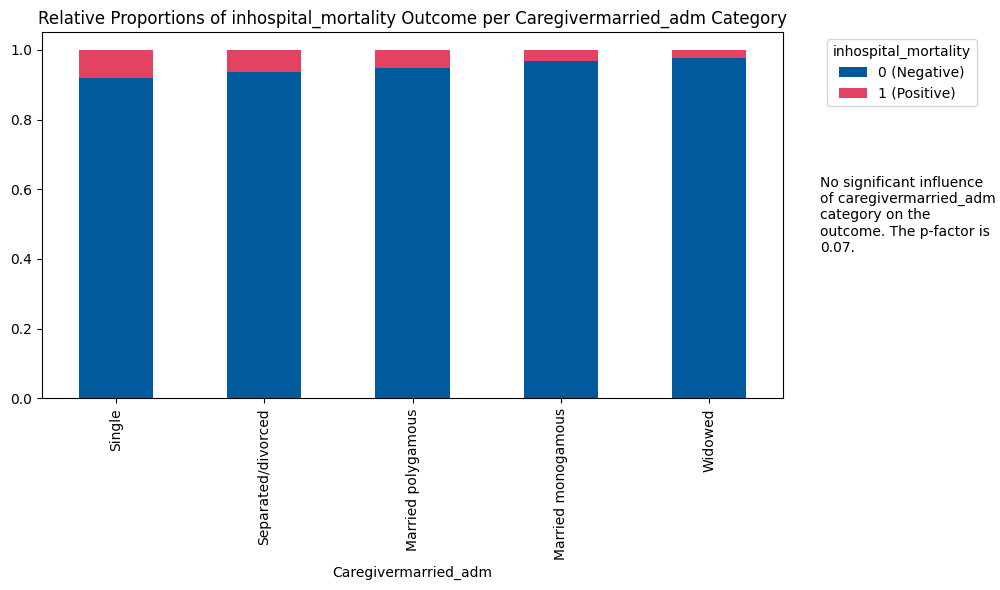

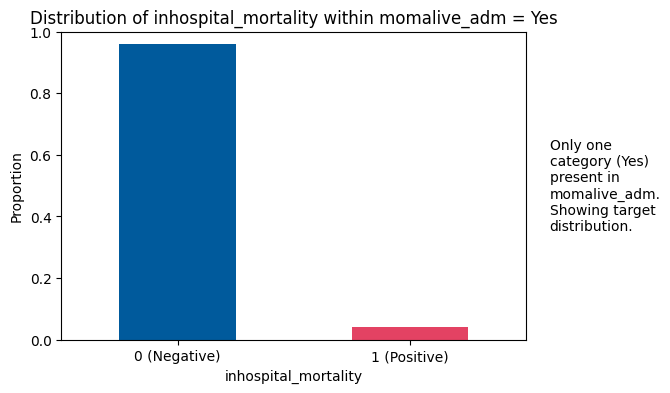

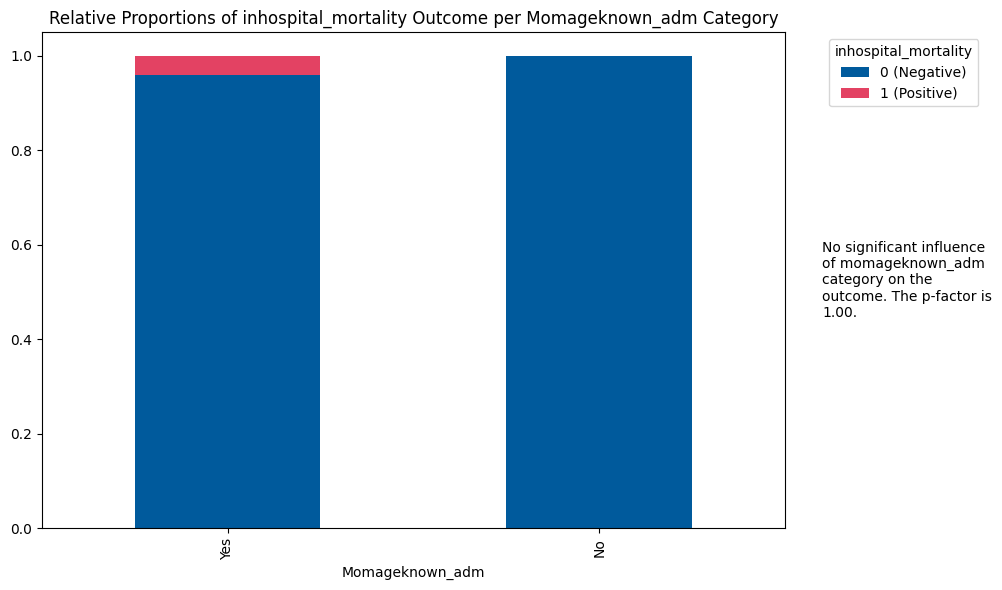

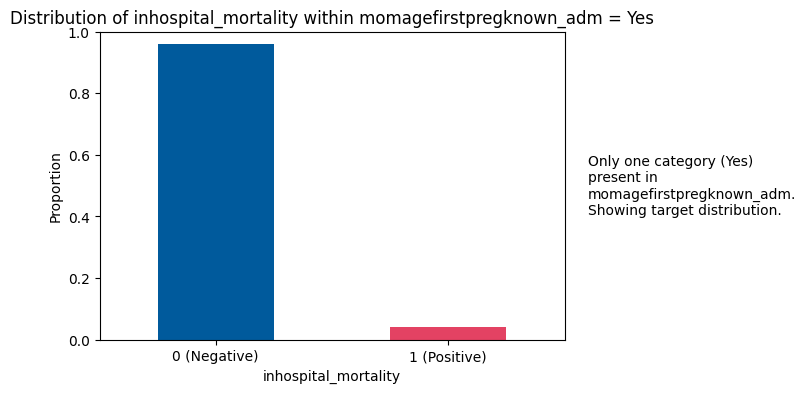

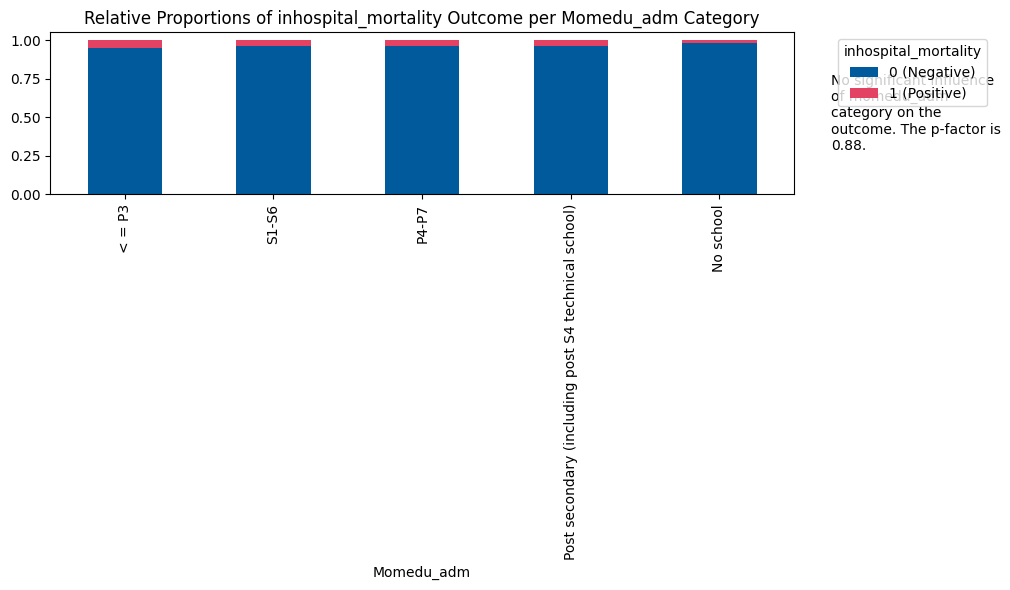

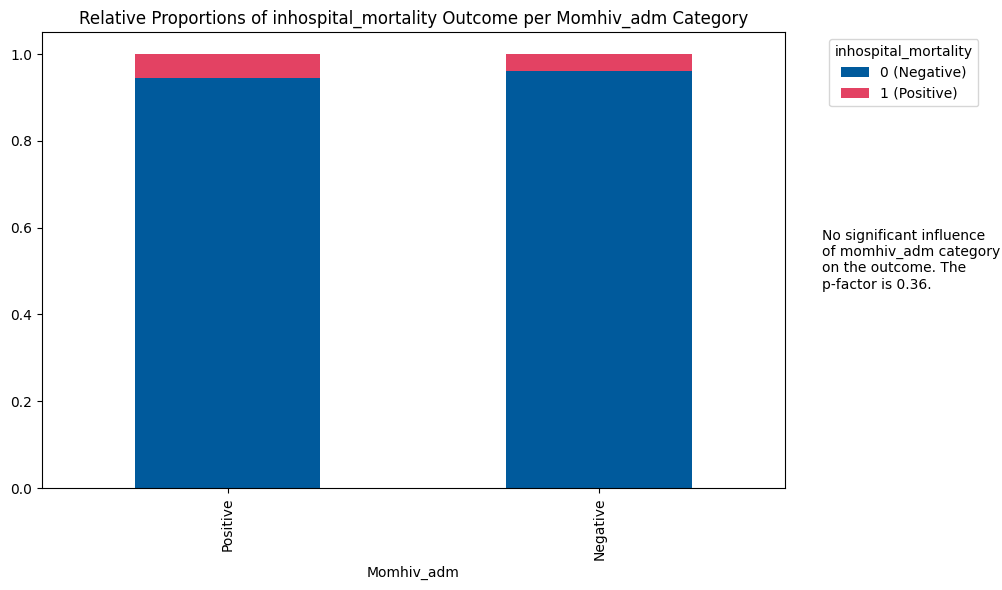

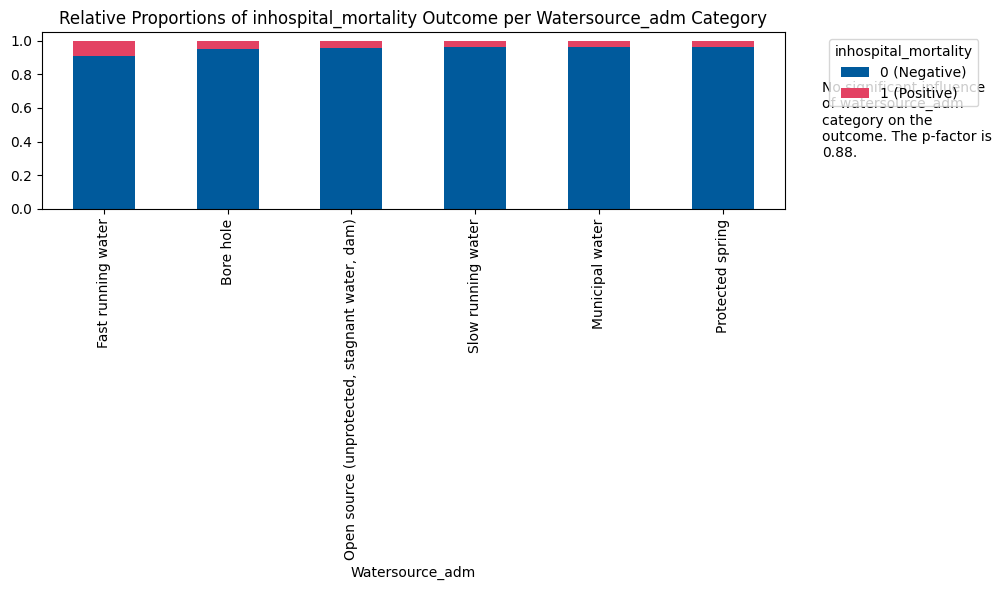

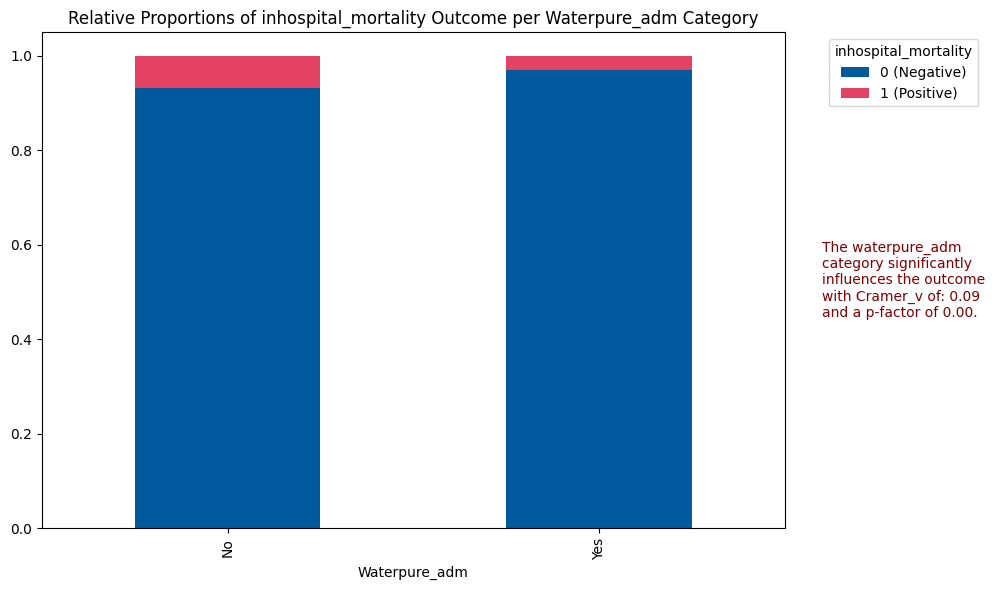

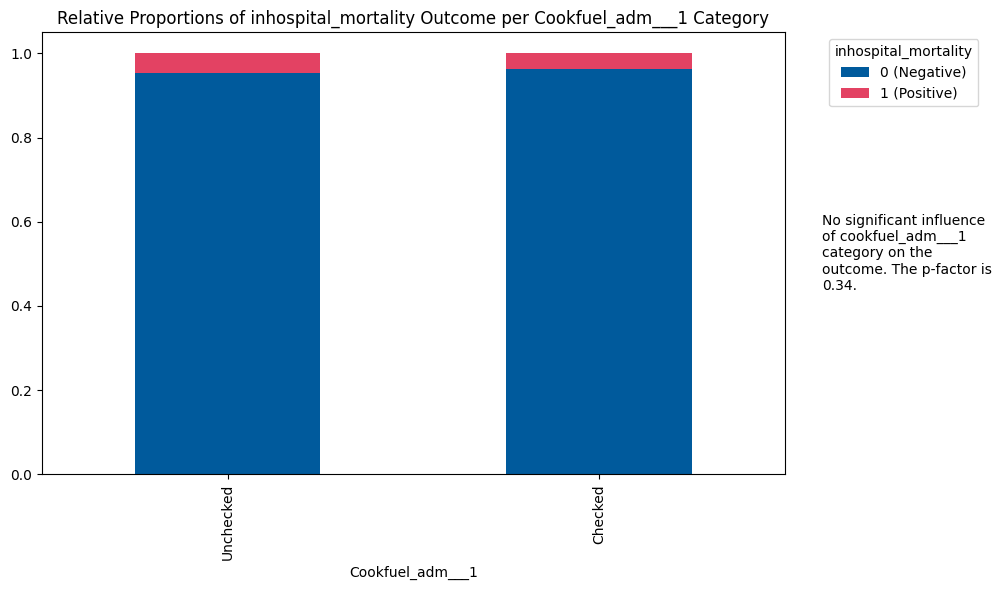

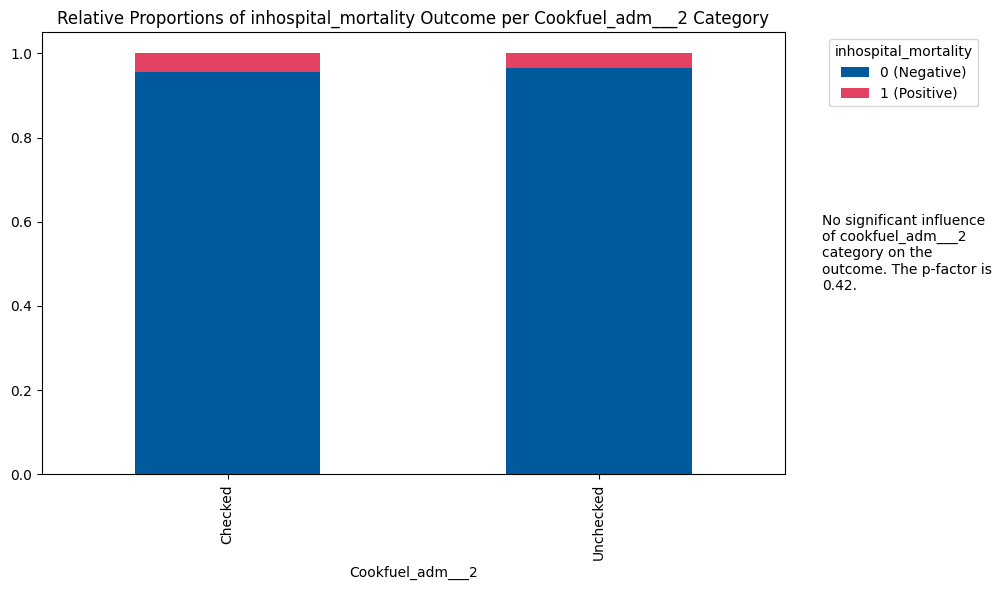

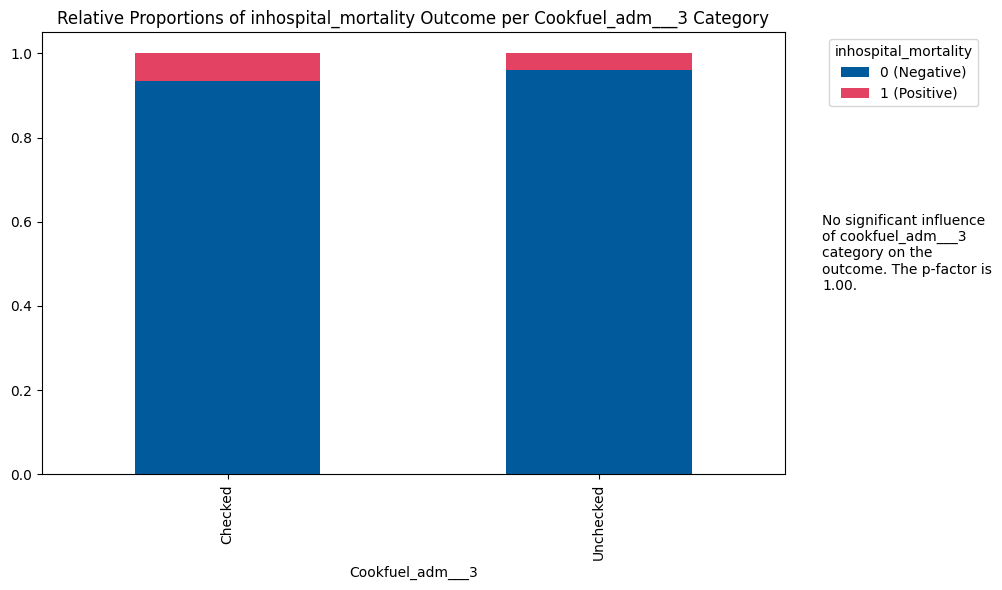

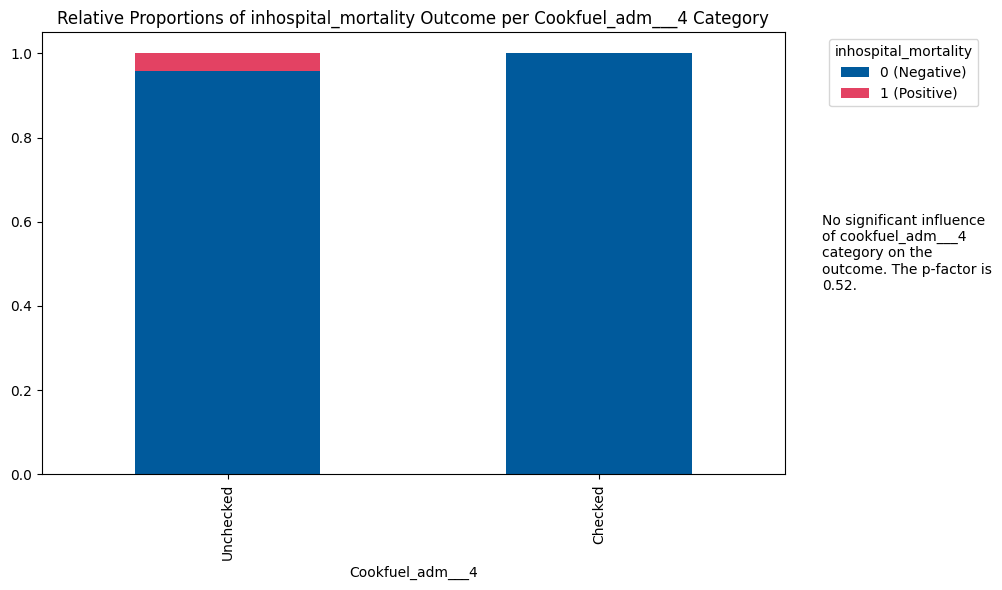

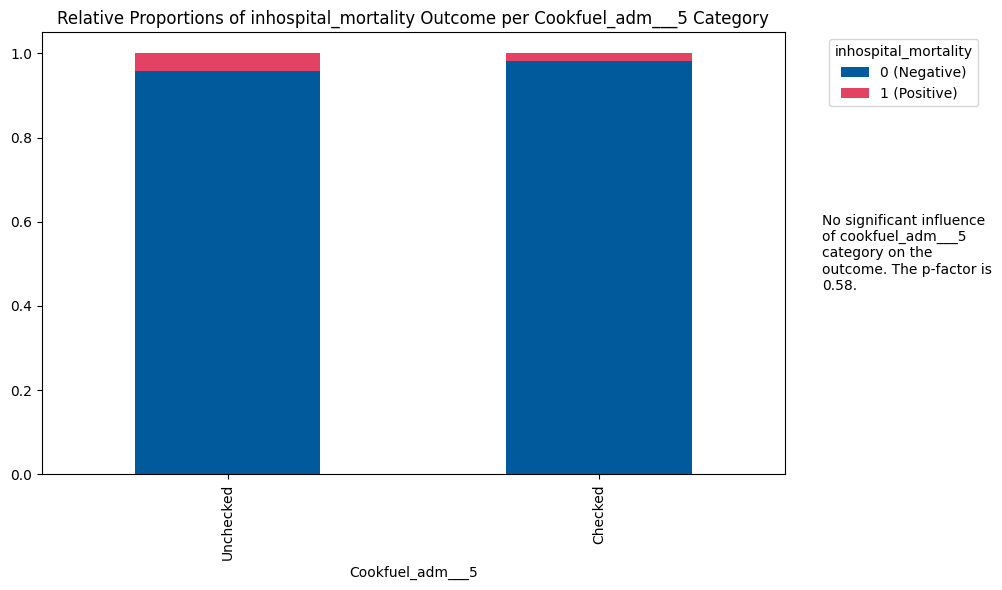

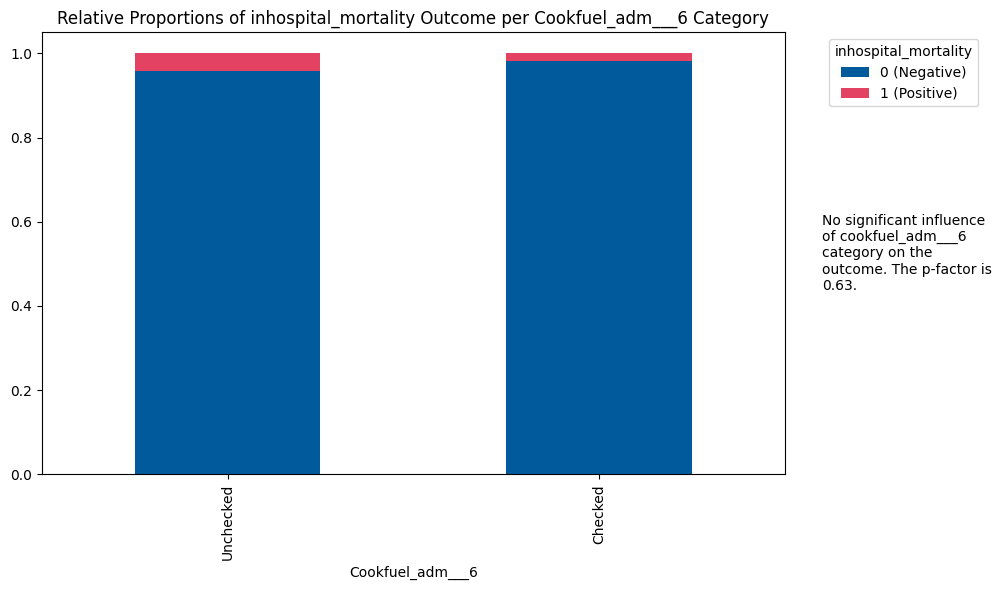

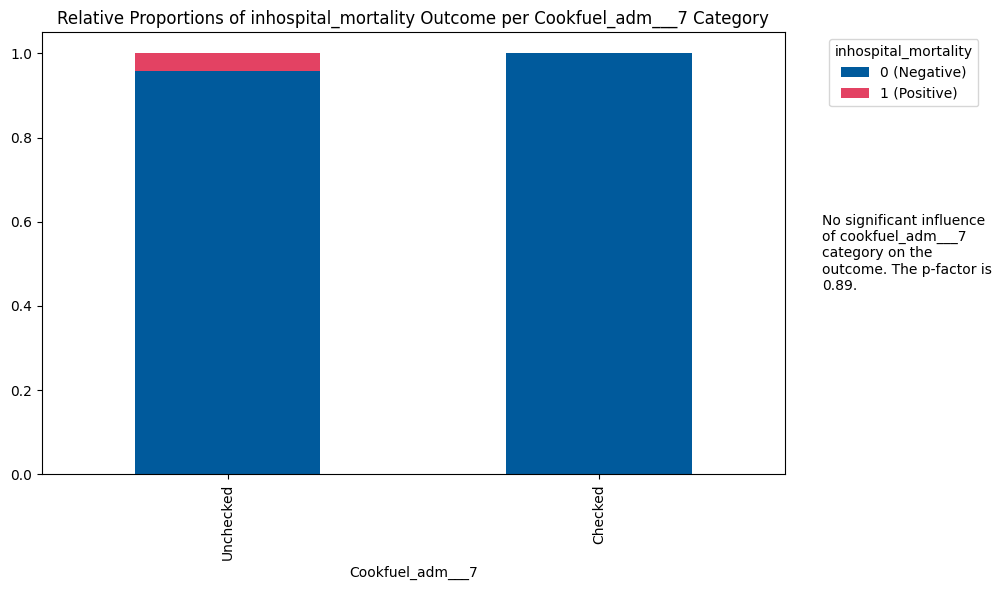

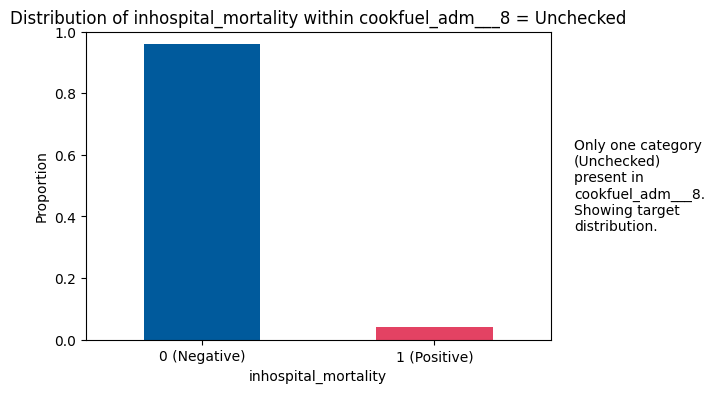

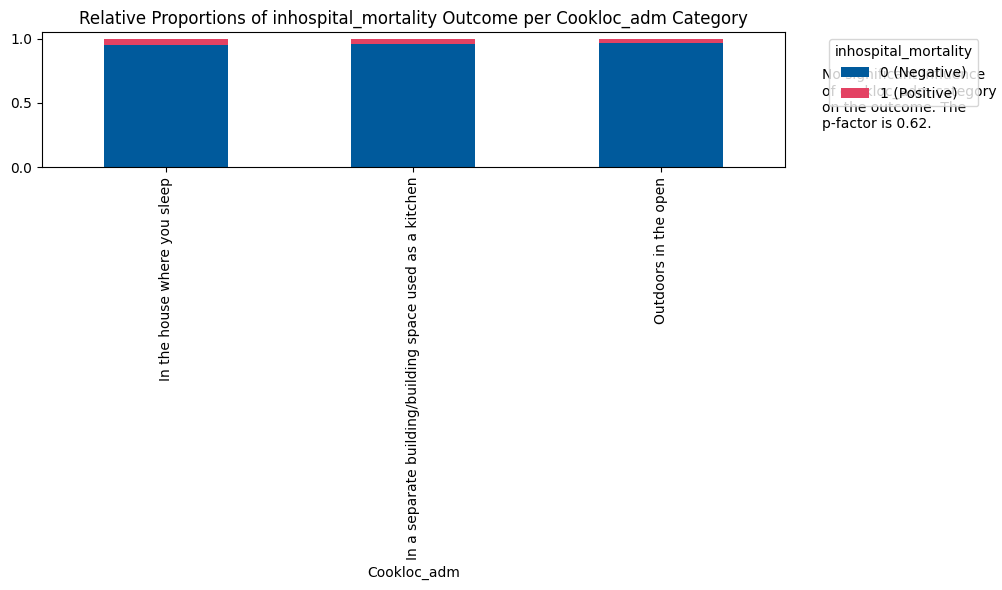

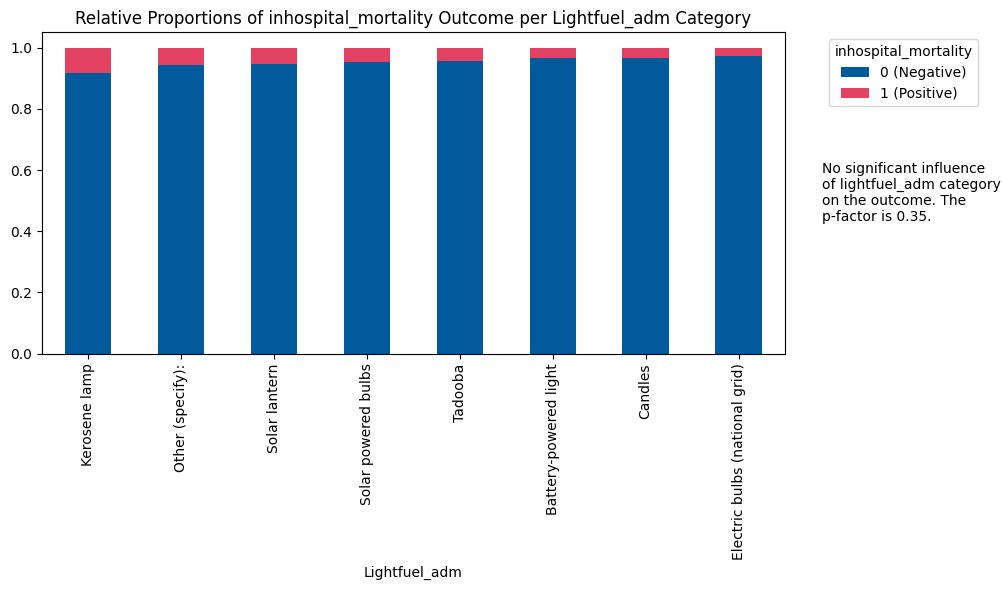

In [ ]:
for col in social_features:
    try:
        categorical_analysis(col, df, target, color=['#005A9C', '#E34263'])
    except Exception as e:
        print(col)
        print(e)